# Лабораторная работа №2
## Классификация. Нейронные сети

**Цель работы:** изучить методы классификации данных с помощью библиотеки Scikit-Learn, реализовать нейронную сеть на TensorFlow/Keras и исследовать процесс обучения с использованием TensorBoard.

**Датасет:** Breast Cancer Wisconsin (Diagnostic).

**Задачи:**
- Выполнить анализ и предобработку данных.
- Разделить выборку на обучающую, валидационную и тестовую в соотношении 60/20/20.
- Реализовать пять методов классификации и исследовать их гиперпараметры.
- Реализовать нейронную сеть и провести эксперименты с её архитектурой.
- Сравнить результаты по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python-библиотеки успешно импортированы!")
print("Scikit-Learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)

Python-библиотеки успешно импортированы!
Scikit-Learn: 1.9.1
TensorFlow: 2.21.0


### 1.1. Характеристика признаков и источник данных

Источник данных — набор Breast Cancer Wisconsin (Diagnostic),
доступный в библиотеке Scikit-Learn.

Ссылка на датасет:
https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

Датасет содержит 569 наблюдений и 30 числовых признаков,
полученных при анализе изображений клеточных ядер.

Признаки описывают десять характеристик:

- radius — радиус;
- texture — текстура;
- perimeter — периметр;
- area — площадь;
- smoothness — гладкость контура;
- compactness — компактность;
- concavity — вогнутость контура;
- concave points — количество вогнутых точек контура;
- symmetry — симметрия;
- fractal dimension — фрактальная размерность.

Для каждой характеристики рассчитываются три группы
показателей: mean (среднее значение), error (стандартная
ошибка) и worst (среднее трёх наибольших значений).

Целевая переменная — диагноз опухоли. В работе
используется кодирование:

- 0 — доброкачественная опухоль;
- 1 — злокачественная опухоль.

Предварительный анализ показал отсутствие пропусков
и полных дубликатов. Поскольку признаки имеют различные
масштабы, для соответствующих методов применяется
стандартизация. Для MultinomialNB и ComplementNB
используется MinMaxScaler.

In [2]:

cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Целевая переменная:
# 0 — доброкачественная опухоль
# 1 — злокачественная опухоль
df["target"] = 1 - cancer.target

print("Размер датасета:", df.shape)
print("\nРаспределение классов:")
print(df["target"].value_counts().sort_index())

print("\nПервые пять строк:")
display(df.head())

Размер датасета: (569, 31)

Распределение классов:
target
0    357
1    212
Name: count, dtype: int64

Первые пять строк:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
print("Информация о датасете:")
df.info()

print("\nКоличество пропущенных значений:")
print(df.isnull().sum().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("\nОписательная статистика:")
display(df.describe())

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness err

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


## 2. Разбиение выборки

Для обучения и оценки моделей исходный датасет разделяется
на три независимые части:

- Обучающая выборка (60%) — используется для обучения моделей.
- Валидационная выборка (20%) — используется для настройки
  гиперпараметров и выбора лучшей модели.
- Тестовая выборка (20%) — используется для итоговой оценки.

Для разделения используется функция train_test_split()
с параметром stratify, обеспечивающим сохранение
соотношения классов.

Для воспроизводимости установлен random_state=42.

In [4]:

X = df.drop(columns=["target"])
y = df["target"]


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=SEED,
    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

print("Обучающая выборка:", X_train.shape)
print("Валидационная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)

print("\nРаспределение классов:")
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    print(labels.value_counts().sort_index())

Обучающая выборка: (341, 30)
Валидационная выборка: (114, 30)
Тестовая выборка: (114, 30)

Распределение классов:

Train:
target
0    214
1    127
Name: count, dtype: int64

Validation:
target
0    71
1    43
Name: count, dtype: int64

Test:
target
0    72
1    42
Name: count, dtype: int64


In [5]:

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)


assert len(X_train) + len(X_val) + len(X_test) == len(df)

print("Разбиение выполнено корректно!")
print("Пересечений между выборками нет.")

Разбиение выполнено корректно!
Пересечений между выборками нет.


## 3. Стандартизация признаков

Для приведения признаков к единому масштабу используется
StandardScaler из библиотеки Scikit-Learn.

Стандартизация преобразует признаки таким образом, чтобы
их среднее значение на обучающей выборке было близко
к нулю, а стандартное отклонение — к единице.

Параметры стандартизации вычисляются только на обучающей
выборке и затем применяются к валидационной и тестовой.
Это позволяет избежать утечки данных.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)


X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Стандартизация завершена!")

print("\nСредние значения первых пяти признаков:")
print(np.round(X_train_scaled.mean(axis=0)[:5], 3))

print("\nСтандартные отклонения первых пяти признаков:")
print(np.round(X_train_scaled.std(axis=0)[:5], 3))

Стандартизация завершена!

Средние значения первых пяти признаков:
[-0. -0.  0. -0.  0.]

Стандартные отклонения первых пяти признаков:
[1. 1. 1. 1. 1.]


## 4. Методы классификации

### 4.1. Наивный байесовский классификатор

Наивный байесовский классификатор основан на теореме Байеса
и предположении об условной независимости признаков.

В работе исследуются четыре варианта:
- GaussianNB — предполагает нормальное распределение признаков.
- MultinomialNB — использует мультиномиальную модель признаков.
- ComplementNB — модификация MultinomialNB, ориентированная
  в том числе на несбалансированные данные.
- BernoulliNB — использует бинарные признаки.

Для GaussianNB используются стандартизированные признаки.
Для MultinomialNB и ComplementNB применяется MinMaxScaler,
поскольку эти модели требуют неотрицательные значения.
Для BernoulliNB применяется бинаризация стандартизированных
признаков.

Гиперпараметры подбираются на валидационной выборке.
Качество оценивается по Accuracy, Precision, Recall,
F1-score и ROC-AUC.

Положительный класс (1) соответствует злокачественной опухоли.

In [7]:
from sklearn.preprocessing import MinMaxScaler

from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    ComplementNB,
    BernoulliNB
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

from pathlib import Path


Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)


minmax_scaler = MinMaxScaler(clip=True)

X_train_minmax = minmax_scaler.fit_transform(X_train)
X_val_minmax = minmax_scaler.transform(X_val)
X_test_minmax = minmax_scaler.transform(X_test)

print("Данные подготовлены для всех вариантов Naive Bayes.")
print("Минимум Train:", X_train_minmax.min())
print("Максимум Train:", X_train_minmax.max())
print("Минимум Validation:", X_val_minmax.min())

Данные подготовлены для всех вариантов Naive Bayes.
Минимум Train: 0.0
Максимум Train: 1.0
Минимум Validation: 0.0


In [8]:
def evaluate_classifier(model, X_data, y_true):

    y_pred = model.predict(X_data)

   
    y_proba = model.predict_proba(X_data)[:, 1]

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_proba)
    }

print("Функция оценки моделей создана!")

Функция оценки моделей создана!


### 4.1.1. Настройка гиперпараметров Naive Bayes

Для исследования влияния гиперпараметров используется
перебор различных комбинаций настроек.

Исследуемые параметры:

- GaussianNB: var_smoothing.
- MultinomialNB: alpha, fit_prior.
- ComplementNB: alpha, norm.
- BernoulliNB: alpha, binarize.

Каждая комбинация обучается на обучающей выборке
и оценивается на валидационной.

Основным критерием выбора является F1-score.
Дополнительно учитываются Recall и ROC-AUC.

In [9]:

bayes_experiments = {
    "GaussianNB": {
        "model": GaussianNB(),
        "params": {
            "var_smoothing": [
                1e-12, 1e-10, 1e-9,
                1e-8, 1e-6, 1e-4
            ]
        },
        "train": X_train_scaled,
        "val": X_val_scaled
    },

    "MultinomialNB": {
        "model": MultinomialNB(),
        "params": {
            "alpha": [0.01, 0.1, 1.0, 10.0],
            "fit_prior": [True, False]
        },
        "train": X_train_minmax,
        "val": X_val_minmax
    },

    "ComplementNB": {
        "model": ComplementNB(),
        "params": {
            "alpha": [0.01, 0.1, 1.0, 10.0],
            "norm": [True, False]
        },
        "train": X_train_minmax,
        "val": X_val_minmax
    },

    "BernoulliNB": {
        "model": BernoulliNB(),
        "params": {
            "alpha": [0.1, 1.0, 10.0],
            "binarize": [0.0, 0.5, 1.0],
            "fit_prior": [True, False]
        },
        "train": X_train_scaled,
        "val": X_val_scaled
    }
}

print("Количество комбинаций параметров:")

for name, config in bayes_experiments.items():
    count = len(list(ParameterGrid(config["params"])))
    print(f"{name}: {count}")

Количество комбинаций параметров:
GaussianNB: 6
MultinomialNB: 8
ComplementNB: 8
BernoulliNB: 18


In [10]:
bayes_results_list = []
best_bayes_models = {}

for name, config in bayes_experiments.items():

    best_score = (-1, -1, -1)
    best_model = None

    for params in ParameterGrid(config["params"]):

        
        model = clone(config["model"])
        model.set_params(**params)

       
        model.fit(config["train"], y_train)

       
        metrics = evaluate_classifier(
            model,
            config["val"],
            y_val
        )

       
        result = {
            "Модель": name,
            "Параметры": str(params),
            **metrics
        }

        bayes_results_list.append(result)

        
        current_score = (
            metrics["F1"],
            metrics["Recall"],
            metrics["ROC-AUC"]
        )

        if current_score > best_score:
            best_score = current_score
            best_model = model

    best_bayes_models[name] = best_model

    print(f"{name}: лучший F1 = {best_score[0]:.4f}")


bayes_results = pd.DataFrame(bayes_results_list)

print("\nВсего проведено экспериментов:", len(bayes_results))
display(bayes_results.round(4))

GaussianNB: лучший F1 = 0.9024
MultinomialNB: лучший F1 = 0.8056
ComplementNB: лучший F1 = 0.7857
BernoulliNB: лучший F1 = 0.9425

Всего проведено экспериментов: 40


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,GaussianNB,{'var_smoothing': 1e-12},0.9298,0.9487,0.8605,0.9024,0.9912
1,GaussianNB,{'var_smoothing': 1e-10},0.9298,0.9487,0.8605,0.9024,0.9912
2,GaussianNB,{'var_smoothing': 1e-09},0.9298,0.9487,0.8605,0.9024,0.9912
3,GaussianNB,{'var_smoothing': 1e-08},0.9298,0.9487,0.8605,0.9024,0.9912
4,GaussianNB,{'var_smoothing': 1e-06},0.9298,0.9487,0.8605,0.9024,0.9912
5,GaussianNB,{'var_smoothing': 0.0001},0.9298,0.9487,0.8605,0.9024,0.9912
6,MultinomialNB,"{'alpha': 0.01, 'fit_prior': True}",0.8772,1.0000,0.6744,0.8056,0.9499
7,MultinomialNB,"{'alpha': 0.01, 'fit_prior': False}",0.7895,0.6727,0.8605,0.7551,0.9499
8,MultinomialNB,"{'alpha': 0.1, 'fit_prior': True}",0.8772,1.0000,0.6744,0.8056,0.9499
9,MultinomialNB,"{'alpha': 0.1, 'fit_prior': False}",0.7895,0.6727,0.8605,0.7551,0.9499


In [11]:

best_bayes_results = (
    bayes_results
    .sort_values(
    ["F1", "Recall", "ROC-AUC"],
    ascending=False,
    kind="stable"
)
    .drop_duplicates(subset=["Модель"])
    .reset_index(drop=True)
)

print("Лучшие конфигурации байесовских классификаторов:")
display(best_bayes_results.round(4))

bayes_results.to_csv(
    "results/bayes_all_experiments.csv",
    index=False
)

best_bayes_results.to_csv(
    "results/bayes_best_models.csv",
    index=False
)

print("Результаты сохранены в папку results.")

Лучшие конфигурации байесовских классификаторов:


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,BernoulliNB,"{'alpha': 1.0, 'binarize': 0.0, 'fit_prior': T...",0.9561,0.9318,0.9535,0.9425,0.9951
1,GaussianNB,{'var_smoothing': 1e-12},0.9298,0.9487,0.8605,0.9024,0.9912
2,MultinomialNB,"{'alpha': 0.01, 'fit_prior': True}",0.8772,1.0000,0.6744,0.8056,0.9499
3,ComplementNB,"{'alpha': 1.0, 'norm': True}",0.8421,0.8049,0.7674,0.7857,0.9286


Результаты сохранены в папку results.


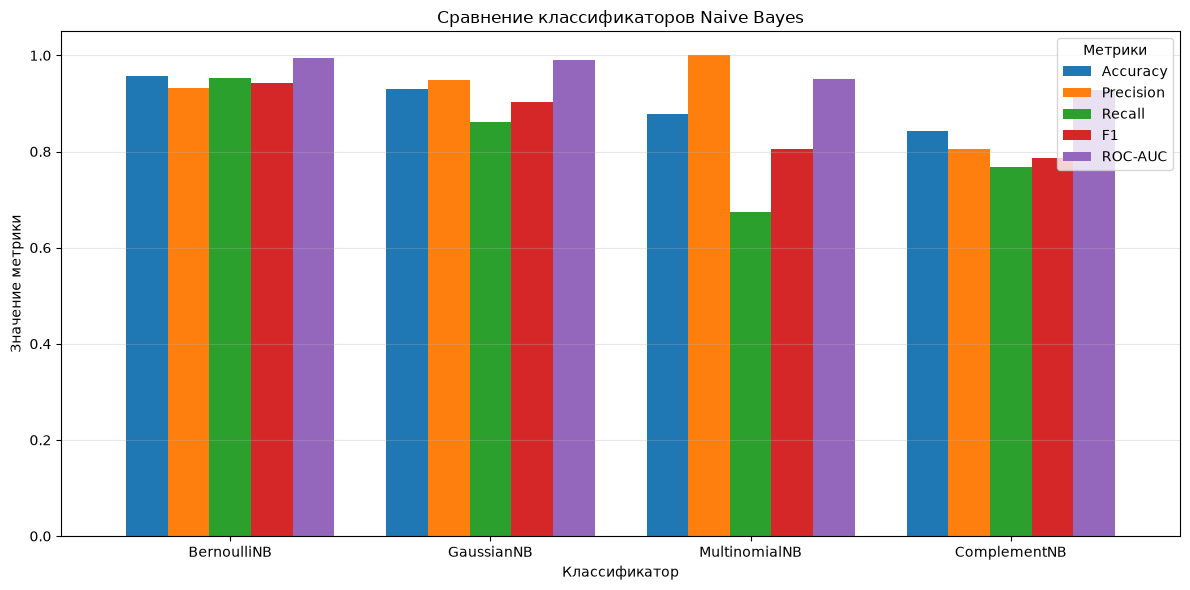

In [12]:
metrics_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

plot_data = best_bayes_results.set_index("Модель")

ax = plot_data[metrics_columns].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Сравнение классификаторов Naive Bayes")
plt.xlabel("Классификатор")
plt.ylabel("Значение метрики")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Метрики")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/bayes_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Выводы по экспериментам Naive Bayes

В ходе исследования проведено 40 экспериментов с четырьмя
вариантами наивного байесовского классификатора.

Наилучший результат на валидационной выборке показал
BernoulliNB: Accuracy = 0.9561, Recall = 0.9535,
F1-score = 0.9425.

Наиболее эффективным оказался порог бинаризации
binarize=0.0. Увеличение порога до 0.5 и 1.0 приводило
к снижению F1-score в исследованных конфигурациях.

Для GaussianNB изменение var_smoothing в диапазоне
от 1e-12 до 1e-4 не повлияло на качество классификации.
F1-score оставался равным 0.9024.

Для MultinomialNB наибольший F1-score составил 0.8056.
При fit_prior=True наблюдалась высокая Precision,
однако Recall оказался сравнительно низким.

Для ComplementNB лучший F1-score составил 0.7857.
Наилучшие результаты получены при norm=True.

Таким образом, среди рассмотренных вариантов Naive Bayes
наиболее эффективным для выбранного датасета оказался
BernoulliNB.

### 4.2. Дерево решений (Decision Tree)

Дерево решений — метод классификации, основанный на
последовательном разделении данных по значениям признаков.

Для исследования качества классификации изменяются
гиперпараметры:

- criterion — критерий разделения узлов;
- max_depth — максимальная глубина дерева;
- min_samples_split — минимальное число объектов для разделения;
- min_samples_leaf — минимальное число объектов в листе.

Для настройки используется валидационная выборка.
Основной критерий выбора модели — F1-score.

Дополнительно исследуется влияние глубины дерева
на качество классификации обучающей и валидационной выборок.

Количество экспериментов: 96

Лучшие гиперпараметры:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}

Метрики лучшей модели:


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,DecisionTree,"{'criterion': 'entropy', 'max_depth': 5, 'min_...",0.9561,0.975,0.907,0.9398,0.9559



10 лучших экспериментов:


,criterion,max_depth,min_samples_split,min_samples_leaf,Train F1,Accuracy,Precision,Recall,F1,ROC-AUC
72,entropy,5,2,1,0.9921,0.9561,0.9750,0.9070,0.9398,0.9559
73,entropy,5,5,1,0.9840,0.9474,0.9744,0.8837,0.9268,0.9538
24,gini,5,2,1,0.9840,0.9474,0.9744,0.8837,0.9268,0.9261
79,entropy,7,5,1,0.9880,0.9386,0.9500,0.8837,0.9157,0.9374
30,gini,7,2,1,1.0000,0.9386,0.9500,0.8837,0.9157,0.9278
36,gini,10,2,1,1.0000,0.9386,0.9500,0.8837,0.9157,0.9278
42,gini,None,2,1,1.0000,0.9386,0.9500,0.8837,0.9157,0.9278
12,gini,3,2,1,0.9547,0.9386,0.9737,0.8605,0.9136,0.9410
13,gini,3,5,1,0.9504,0.9386,0.9737,0.8605,0.9136,0.9410
14,gini,3,10,1,0.9504,0.9386,0.9737,0.8605,0.9136,0.9410


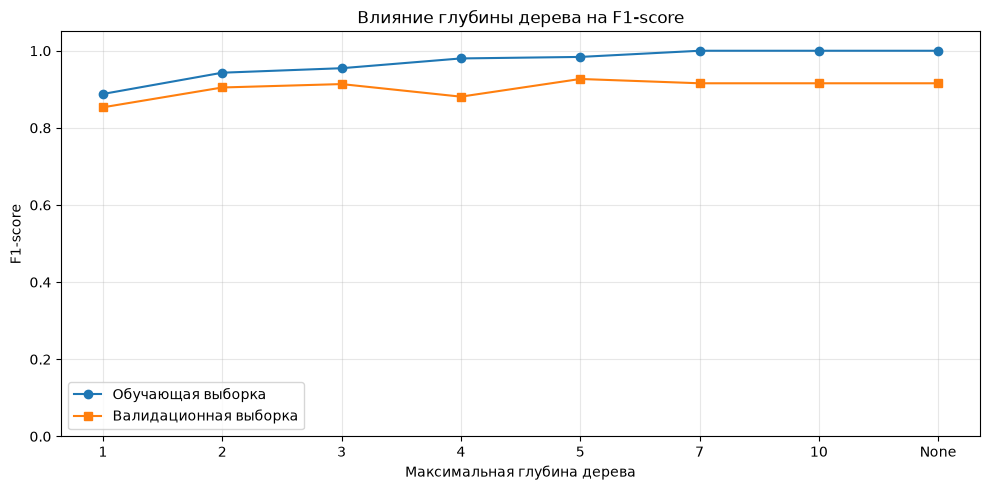


Результаты Decision Tree сохранены!


In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score

tree_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [1, 2, 3, 4, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 3]
}

tree_results_list = []

best_tree_model = None
best_tree_params = None
best_tree_metrics = None
best_tree_score = (-1, -1, -1)

for params in ParameterGrid(tree_param_grid):

    model = DecisionTreeClassifier(
        random_state=SEED,
        **params
    )


    model.fit(X_train, y_train)

    
    metrics = evaluate_classifier(model, X_val, y_val)

   
    train_f1 = f1_score(
        y_train,
        model.predict(X_train)
    )

    tree_results_list.append({
        "criterion": params["criterion"],
        "max_depth": str(params["max_depth"]),
        "min_samples_split": params["min_samples_split"],
        "min_samples_leaf": params["min_samples_leaf"],
        "Train F1": train_f1,
        **metrics
    })

    
    current_score = (
        metrics["F1"],
        metrics["Recall"],
        metrics["ROC-AUC"]
    )

    if current_score > best_tree_score:
        best_tree_score = current_score
        best_tree_model = model
        best_tree_params = params.copy()
        best_tree_metrics = metrics.copy()


tree_results = pd.DataFrame(tree_results_list)

print("Количество экспериментов:", len(tree_results))
print("\nЛучшие гиперпараметры:")
print(best_tree_params)

print("\nМетрики лучшей модели:")

tree_best_result = pd.DataFrame([{
    "Модель": "DecisionTree",
    "Параметры": str(best_tree_params),
    **best_tree_metrics
}])

display(tree_best_result.round(4))

print("\n10 лучших экспериментов:")

display(
    tree_results.sort_values(
        ["F1", "Recall", "ROC-AUC"],
        ascending=False,
        kind="stable"
    ).head(10).round(4)
)

tree_results.to_csv(
    "results/tree_all_experiments.csv",
    index=False
)

tree_best_result.to_csv(
    "results/tree_best_model.csv",
    index=False
)


depth_order = ["1", "2", "3", "4", "5", "7", "10", "None"]

depth_results = tree_results[
    (tree_results["criterion"] == "gini") &
    (tree_results["min_samples_split"] == 2) &
    (tree_results["min_samples_leaf"] == 1)
].set_index("max_depth").loc[depth_order]

plt.figure(figsize=(10, 5))

plt.plot(
    depth_order,
    depth_results["Train F1"],
    marker="o",
    label="Обучающая выборка"
)

plt.plot(
    depth_order,
    depth_results["F1"],
    marker="s",
    label="Валидационная выборка"
)

plt.title("Влияние глубины дерева на F1-score")
plt.xlabel("Максимальная глубина дерева")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/tree_depth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nРезультаты Decision Tree сохранены!")

#### Выводы по экспериментам Decision Tree

Для дерева решений проведено 96 экспериментов с изменением
criterion, max_depth, min_samples_split и min_samples_leaf.

Лучшие гиперпараметры:
- criterion = entropy;
- max_depth = 5;
- min_samples_split = 2;
- min_samples_leaf = 1.

На валидационной выборке получены:
Accuracy = 0.9561, F1-score = 0.9398.

Исследование влияния глубины дерева показало, что
увеличение max_depth улучшает качество на обучающей
выборке, однако не всегда повышает качество на валидации.

При использовании criterion=gini и глубине от 7
F1-score на обучающей выборке достигал 1.0, тогда как
на валидационной оставался около 0.9157.

Это свидетельствует о переобучении глубоких деревьев.

Таким образом, ограничение глубины дерева позволяет
контролировать сложность модели и улучшать её способность
к обобщению.

### 4.3. Линейный дискриминантный анализ (LDA)

Линейный дискриминантный анализ — метод классификации,
основанный на поиске линейных границ между классами.

В работе исследуется влияние гиперпараметров:
- solver — алгоритм решения задачи;
- tol — порог определения значимых компонент;
- shrinkage — степень регуляризации ковариационной матрицы.

Для обучения используются стандартизированные признаки.

Каждая конфигурация обучается на обучающей выборке
и оценивается на валидационной выборке.

Качество моделей сравнивается по метрикам Accuracy,
Precision, Recall, F1-score и ROC-AUC.

Основной критерий выбора лучшей модели — F1-score.

Количество экспериментов: 12

Результаты всех экспериментов:


,Конфигурация,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,"svd, tol=1e-05","{'solver': 'svd', 'tol': 1e-05}",0.9649,1.0000,0.9070,0.9512,0.9990
1,"svd, tol=0.0001","{'solver': 'svd', 'tol': 0.0001}",0.9649,1.0000,0.9070,0.9512,0.9990
2,"svd, tol=0.001","{'solver': 'svd', 'tol': 0.001}",0.9649,1.0000,0.9070,0.9512,0.9990
3,"svd, tol=0.01","{'solver': 'svd', 'tol': 0.01}",0.9649,1.0000,0.9070,0.9512,0.9990
4,"lsqr, shrinkage=None","{'solver': 'lsqr', 'shrinkage': None}",0.9649,1.0000,0.9070,0.9512,0.9990
5,"lsqr, shrinkage=auto","{'solver': 'lsqr', 'shrinkage': 'auto'}",0.9561,1.0000,0.8837,0.9383,0.9993
6,"lsqr, shrinkage=0.0","{'solver': 'lsqr', 'shrinkage': 0.0}",0.9649,1.0000,0.9070,0.9512,0.9990
7,"lsqr, shrinkage=0.1","{'solver': 'lsqr', 'shrinkage': 0.1}",0.9561,1.0000,0.8837,0.9383,0.9997
8,"lsqr, shrinkage=0.3","{'solver': 'lsqr', 'shrinkage': 0.3}",0.9386,1.0000,0.8372,0.9114,1.0000
9,"lsqr, shrinkage=0.5","{'solver': 'lsqr', 'shrinkage': 0.5}",0.9474,1.0000,0.8605,0.9250,0.9997



Лучшие гиперпараметры:
{'solver': 'svd', 'tol': 1e-05}

Метрики лучшей модели:


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,LDA,"{'solver': 'svd', 'tol': 1e-05}",0.9649,1.0,0.907,0.9512,0.999


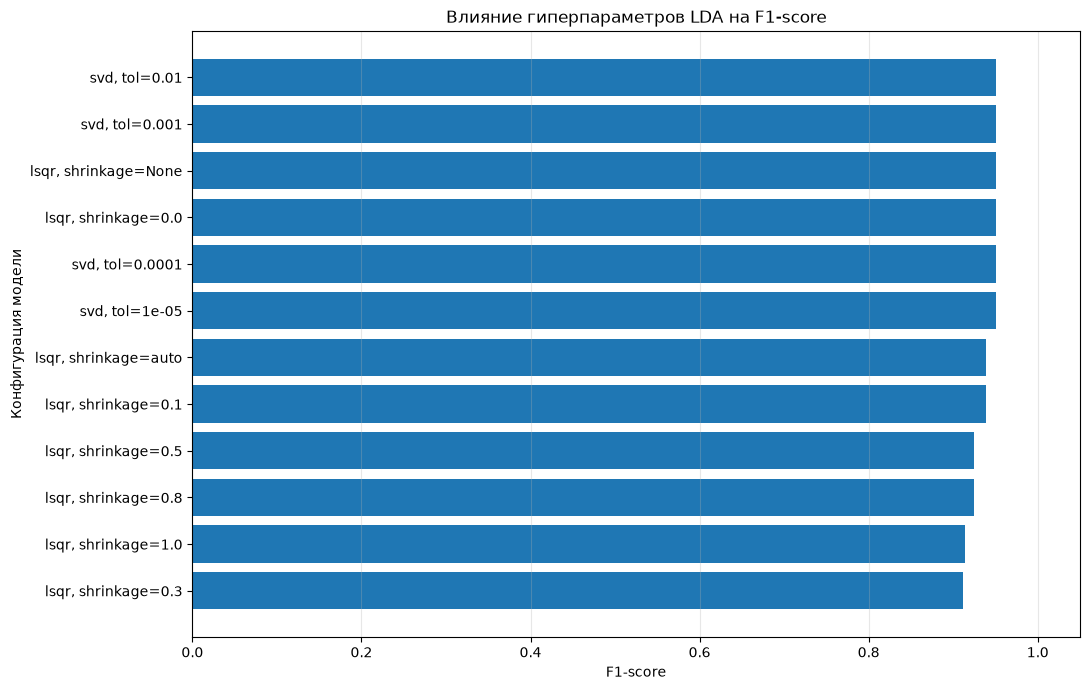


Результаты LDA сохранены!


In [14]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_configs = (
    [
        {"solver": "svd", "tol": tol}
        for tol in [1e-5, 1e-4, 1e-3, 1e-2]
    ]
    +
    [
        {"solver": "lsqr", "shrinkage": shrinkage}
        for shrinkage in [None, "auto", 0.0, 0.1, 0.3, 0.5, 0.8, 1.0]
    ]
)

lda_results_list = []

best_lda_model = None
best_lda_params = None
best_lda_metrics = None
best_lda_score = (-1, -1, -1)

for params in lda_configs:

    model = LinearDiscriminantAnalysis(**params)

    model.fit(X_train_scaled, y_train)

    metrics = evaluate_classifier(
        model,
        X_val_scaled,
        y_val
    )

    if params["solver"] == "svd":
        label = f"svd, tol={params['tol']}"
    else:
        label = f"lsqr, shrinkage={params['shrinkage']}"

    lda_results_list.append({
        "Конфигурация": label,
        "Параметры": str(params),
        **metrics
    })

    current_score = (
        metrics["F1"],
        metrics["Recall"],
        metrics["ROC-AUC"]
    )

    if current_score > best_lda_score:
        best_lda_score = current_score
        best_lda_model = model
        best_lda_params = params.copy()
        best_lda_metrics = metrics.copy()


lda_results = pd.DataFrame(lda_results_list)

print("Количество экспериментов:", len(lda_results))

print("\nРезультаты всех экспериментов:")
display(lda_results.round(4))

print("\nЛучшие гиперпараметры:")
print(best_lda_params)

lda_best_result = pd.DataFrame([{
    "Модель": "LDA",
    "Параметры": str(best_lda_params),
    **best_lda_metrics
}])

print("\nМетрики лучшей модели:")
display(lda_best_result.round(4))


lda_results.to_csv(
    "results/lda_all_experiments.csv",
    index=False
)

lda_best_result.to_csv(
    "results/lda_best_model.csv",
    index=False
)

lda_plot = lda_results.sort_values("F1")

plt.figure(figsize=(11, 7))

plt.barh(
    lda_plot["Конфигурация"],
    lda_plot["F1"]
)

plt.title("Влияние гиперпараметров LDA на F1-score")
plt.xlabel("F1-score")
plt.ylabel("Конфигурация модели")
plt.xlim(0, 1.05)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/lda_hyperparams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nРезультаты LDA сохранены!")

#### Выводы по экспериментам LDA

В ходе исследования проведено 12 экспериментов
с изменением solver, tol и shrinkage.

Лучший результат на валидационной выборке получен при
solver=svd и tol=1e-5:

Accuracy = 0.9649,
Precision = 1.0000,
Recall = 0.9070,
F1-score = 0.9512,
ROC-AUC = 0.9990.

Изменение tol в диапазоне от 1e-5 до 0.01 не повлияло
на качество классификации.

Для solver=lsqr увеличение shrinkage в большинстве
рассмотренных случаев приводило к снижению F1-score.

При shrinkage=0.3 показатель ROC-AUC достиг 1.0000,
однако F1-score составил 0.9114.

Таким образом, максимальное значение ROC-AUC не всегда
соответствует максимальному F1-score.

Линейный дискриминантный анализ продемонстрировал
высокое качество классификации и превзошёл дерево
решений и байесовские классификаторы по F1-score.

### 4.4. Метод опорных векторов (SVM)

Метод опорных векторов (Support Vector Machines) строит
разделяющую гиперплоскость между классами, обеспечивая
максимальный зазор между ними.

В работе исследуются гиперпараметры:
- kernel — тип ядра (linear, rbf, poly, sigmoid);
- C — параметр регуляризации;
- gamma — коэффициент ядра;
- degree — степень полиномиального ядра.

Для обучения используются стандартизированные признаки.
Гиперпараметры подбираются на валидационной выборке.

Качество оценивается по Accuracy, Precision, Recall,
F1-score и ROC-AUC. Лучший вариант выбирается по F1-score
с дополнительным учётом Recall и ROC-AUC.

Количество экспериментов: 30

Лучшие гиперпараметры:
{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}

Метрики лучшей модели:


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,SVM,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.9737,1.0,0.9302,0.9639,0.9961



10 лучших экспериментов:


,kernel,C,gamma,degree,Параметры,Train F1,Accuracy,Precision,Recall,F1,ROC-AUC
9,rbf,10.0,scale,-,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.9880,0.9737,1.0000,0.9302,0.9639,0.9961
11,rbf,10.0,0.1,-,"{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",1.0000,0.9649,0.9756,0.9302,0.9524,0.9905
10,rbf,10.0,0.01,-,"{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.9840,0.9649,1.0000,0.9070,0.9512,1.0000
0,linear,0.1,-,-,"{'C': 0.1, 'kernel': 'linear'}",0.9801,0.9649,1.0000,0.9070,0.9512,0.9997
1,linear,1.0,-,-,"{'C': 1, 'kernel': 'linear'}",0.9841,0.9649,1.0000,0.9070,0.9512,0.9964
8,rbf,1.0,0.1,-,"{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}",0.9840,0.9561,0.9524,0.9302,0.9412,0.9918
2,linear,10.0,-,-,"{'C': 10, 'kernel': 'linear'}",0.9881,0.9561,0.9750,0.9070,0.9398,0.9957
28,sigmoid,10.0,0.01,-,"{'C': 10, 'gamma': 0.01, 'kernel': 'sigmoid'}",0.9478,0.9561,1.0000,0.8837,0.9383,0.9993
23,poly,10.0,0.1,3,"{'C': 10, 'degree': 3, 'gamma': 0.1, 'kernel':...",1.0000,0.9474,0.9744,0.8837,0.9268,0.9961
25,sigmoid,0.1,0.1,-,"{'C': 0.1, 'gamma': 0.1, 'kernel': 'sigmoid'}",0.9046,0.9474,0.9744,0.8837,0.9268,0.9951


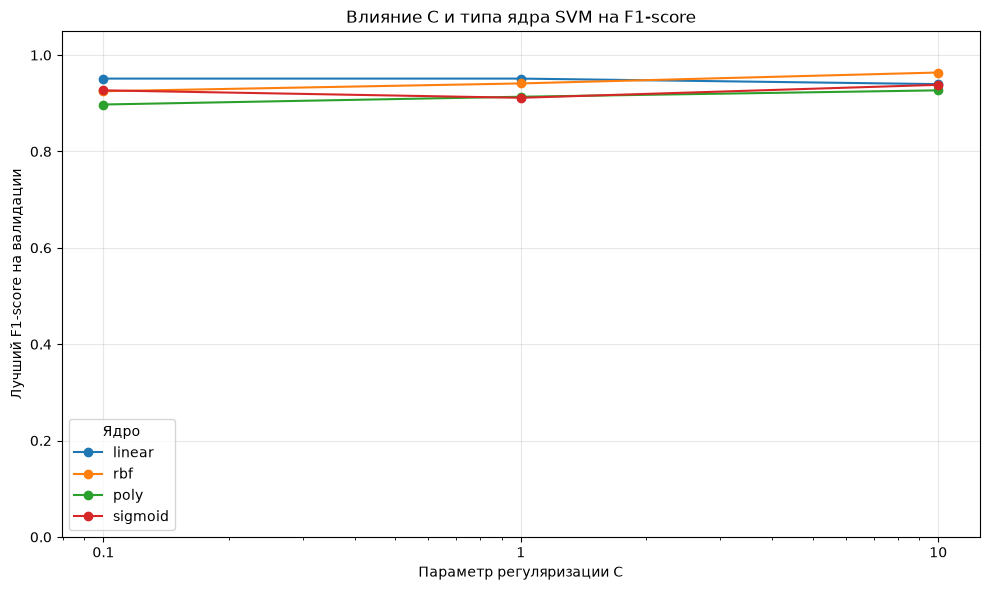


Результаты SVM сохранены!


In [15]:
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)


def evaluate_classifier(model, X_data, y_true):
    y_pred = model.predict(X_data)

    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_data)[:, 1]
    else:
        y_scores = model.decision_function(X_data)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_scores)
    }



svm_param_grid = [
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10]
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10],
        "gamma": ["scale", 0.01, 0.1]
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10],
        "gamma": [0.01, 0.1],
        "degree": [2, 3]
    },
    {
        "kernel": ["sigmoid"],
        "C": [0.1, 1, 10],
        "gamma": [0.01, 0.1]
    }
]

svm_results_list = []

best_svm_model = None
best_svm_params = None
best_svm_metrics = None
best_svm_score = (-1, -1, -1)



for params in ParameterGrid(svm_param_grid):

    model = SVC(
        random_state=SEED,
        **params
    )

    model.fit(X_train_scaled, y_train)

    metrics = evaluate_classifier(
        model,
        X_val_scaled,
        y_val
    )

    train_f1 = f1_score(
        y_train,
        model.predict(X_train_scaled)
    )

    svm_results_list.append({
        "kernel": params["kernel"],
        "C": params["C"],
        "gamma": params.get("gamma", "-"),
        "degree": params.get("degree", "-"),
        "Параметры": str(params),
        "Train F1": train_f1,
        **metrics
    })

    current_score = (
        metrics["F1"],
        metrics["Recall"],
        metrics["ROC-AUC"]
    )

    if current_score > best_svm_score:
        best_svm_score = current_score
        best_svm_model = model
        best_svm_params = params.copy()
        best_svm_metrics = metrics.copy()


svm_results = pd.DataFrame(svm_results_list)

print("Количество экспериментов:", len(svm_results))

print("\nЛучшие гиперпараметры:")
print(best_svm_params)

svm_best_result = pd.DataFrame([{
    "Модель": "SVM",
    "Параметры": str(best_svm_params),
    **best_svm_metrics
}])

print("\nМетрики лучшей модели:")
display(svm_best_result.round(4))

print("\n10 лучших экспериментов:")
display(
    svm_results.sort_values(
        ["F1", "Recall", "ROC-AUC"],
        ascending=False,
        kind="stable"
    ).head(10).round(4)
)


svm_results.to_csv(
    "results/svm_all_experiments.csv",
    index=False
)

svm_best_result.to_csv(
    "results/svm_best_model.csv",
    index=False
)


svm_plot = (
    svm_results
    .groupby(["kernel", "C"], as_index=False)["F1"]
    .max()
)

plt.figure(figsize=(10, 6))

for kernel in ["linear", "rbf", "poly", "sigmoid"]:

    data = svm_plot[svm_plot["kernel"] == kernel]

    plt.plot(
        data["C"],
        data["F1"],
        marker="o",
        label=kernel
    )

plt.xscale("log")
plt.xticks([0.1, 1, 10], ["0.1", "1", "10"])
plt.title("Влияние C и типа ядра SVM на F1-score")
plt.xlabel("Параметр регуляризации C")
plt.ylabel("Лучший F1-score на валидации")
plt.ylim(0, 1.05)
plt.legend(title="Ядро")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/svm_hyperparams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nРезультаты SVM сохранены!")

#### Выводы по экспериментам SVM

Для метода опорных векторов проведено 30 экспериментов
с различными типами ядер и гиперпараметрами.

Наилучшая конфигурация:
- kernel = rbf;
- C = 10;
- gamma = scale.

На валидационной выборке получены:
Accuracy = 0.9737,
Precision = 1.0000,
Recall = 0.9302,
F1-score = 0.9639,
ROC-AUC = 0.9961.

Исследование показало, что выбор ядра и параметра C
заметно влияет на качество классификации.

Увеличение C до 10 повысило качество лучшей конфигурации
с ядром RBF.

Линейное ядро также продемонстрировало высокую
эффективность, однако уступило лучшей RBF-модели.

Полиномиальное и сигмоидальное ядра показали более
низкие максимальные значения F1-score.

Таким образом, SVM с ядром RBF оказался лучшим
среди исследованных классических методов
по F1-score на валидационной выборке.

### 4.5. Метод ближайших соседей (kNN)

Метод k-Nearest Neighbors (kNN) классифицирует объекты
на основе классов ближайших соседей в пространстве признаков.

В работе исследуются следующие гиперпараметры:

- n_neighbors — количество ближайших соседей;
- weights — способ учёта соседей (uniform или distance);
- p — параметр метрики расстояния (1 — манхэттенское,
  2 — евклидово).

Для обучения используются стандартизированные признаки,
поскольку kNN чувствителен к масштабу данных.

Подбор гиперпараметров выполняется на валидационной выборке.
Оценка проводится по Accuracy, Precision, Recall,
F1-score и ROC-AUC.

Основной критерий выбора модели — F1-score.

Количество экспериментов: 32

Лучшие гиперпараметры:
{'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}

Метрики лучшей модели:


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,kNN,"{'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}",0.9561,0.975,0.907,0.9398,0.9464



10 лучших экспериментов:


,n_neighbors,weights,p,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,uniform,1,"{'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}",0.9561,0.975,0.9070,0.9398,0.9464
1,1,distance,1,"{'n_neighbors': 1, 'p': 1, 'weights': 'distance'}",0.9561,0.975,0.9070,0.9398,0.9464
2,1,uniform,2,"{'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}",0.9561,0.975,0.9070,0.9398,0.9464
3,1,distance,2,"{'n_neighbors': 1, 'p': 2, 'weights': 'distance'}",0.9561,0.975,0.9070,0.9398,0.9464
11,5,distance,2,"{'n_neighbors': 5, 'p': 2, 'weights': 'distance'}",0.9561,1.000,0.8837,0.9383,0.9967
10,5,uniform,2,"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}",0.9561,1.000,0.8837,0.9383,0.9959
7,3,distance,2,"{'n_neighbors': 3, 'p': 2, 'weights': 'distance'}",0.9561,1.000,0.8837,0.9383,0.9754
6,3,uniform,2,"{'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}",0.9561,1.000,0.8837,0.9383,0.9751
5,3,distance,1,"{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}",0.9561,1.000,0.8837,0.9383,0.9748
4,3,uniform,1,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}",0.9561,1.000,0.8837,0.9383,0.9743


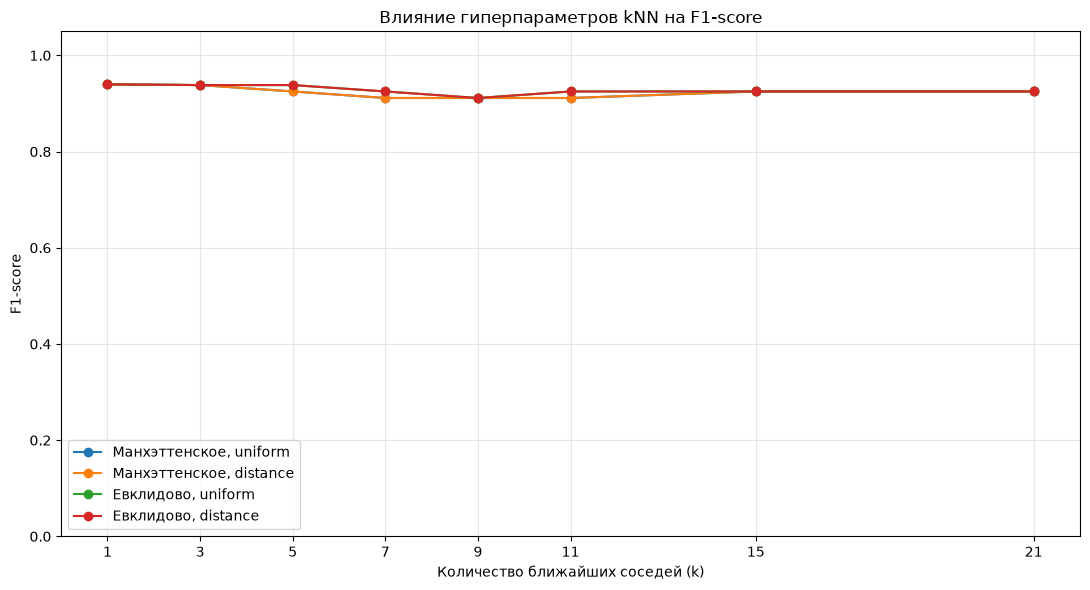


Результаты kNN сохранены!


In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

knn_param_grid = {
    "n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

knn_results_list = []

best_knn_model = None
best_knn_params = None
best_knn_metrics = None
best_knn_score = (-1, -1, -1)


for params in ParameterGrid(knn_param_grid):

    model = KNeighborsClassifier(**params)

    model.fit(X_train_scaled, y_train)

    metrics = evaluate_classifier(
        model,
        X_val_scaled,
        y_val
    )

    knn_results_list.append({
        "n_neighbors": params["n_neighbors"],
        "weights": params["weights"],
        "p": params["p"],
        "Параметры": str(params),
        **metrics
    })

    current_score = (
        metrics["F1"],
        metrics["Recall"],
        metrics["ROC-AUC"]
    )

    if current_score > best_knn_score:
        best_knn_score = current_score
        best_knn_model = model
        best_knn_params = params.copy()
        best_knn_metrics = metrics.copy()


knn_results = pd.DataFrame(knn_results_list)

print("Количество экспериментов:", len(knn_results))

print("\nЛучшие гиперпараметры:")
print(best_knn_params)

knn_best_result = pd.DataFrame([{
    "Модель": "kNN",
    "Параметры": str(best_knn_params),
    **best_knn_metrics
}])

print("\nМетрики лучшей модели:")
display(knn_best_result.round(4))

print("\n10 лучших экспериментов:")
display(
    knn_results.sort_values(
        ["F1", "Recall", "ROC-AUC"],
        ascending=False,
        kind="stable"
    ).head(10).round(4)
)



knn_results.to_csv(
    "results/knn_all_experiments.csv",
    index=False
)

knn_best_result.to_csv(
    "results/knn_best_model.csv",
    index=False
)


plt.figure(figsize=(11, 6))

for p in [1, 2]:
    for weights in ["uniform", "distance"]:

        data = knn_results[
            (knn_results["p"] == p) &
            (knn_results["weights"] == weights)
        ].sort_values("n_neighbors")

        distance_name = (
            "Манхэттенское" if p == 1 else "Евклидово"
        )

        plt.plot(
            data["n_neighbors"],
            data["F1"],
            marker="o",
            label=f"{distance_name}, {weights}"
        )

plt.title("Влияние гиперпараметров kNN на F1-score")
plt.xlabel("Количество ближайших соседей (k)")
plt.ylabel("F1-score")

plt.xticks([1, 3, 5, 7, 9, 11, 15, 21])
plt.ylim(0, 1.05)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/knn_hyperparams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nРезультаты kNN сохранены!")

#### Выводы по экспериментам kNN

Для метода ближайших соседей проведено 32 эксперимента
с изменением количества соседей, способа взвешивания
и метрики расстояния.

Лучшие гиперпараметры:
- n_neighbors = 1;
- weights = uniform;
- p = 1.

На валидационной выборке получены:
Accuracy = 0.9561,
Precision = 0.9750,
Recall = 0.9070,
F1-score = 0.9398,
ROC-AUC = 0.9464.

При k=1 все четыре исследованные конфигурации
показали одинаковый F1-score.

При увеличении количества соседей качество изменялось
незначительно.

Для конфигурации k=5, p=2, weights=distance значение
ROC-AUC достигло 0.9967, но F1-score было ниже — 0.9383.

Таким образом, kNN продемонстрировал достаточно высокое
качество классификации, однако уступил SVM и LDA
по основному критерию F1-score.

## 5. Нейронная сеть на TensorFlow/Keras

Для решения задачи бинарной классификации разработана
полносвязная нейронная сеть на TensorFlow/Keras.

Архитектура базовой сети:
- Входной слой - 30 признаков;
- Скрытый слой Dense - 32 нейрона, активация ReLU;
- Выходной слой Dense - 1 нейрон, активация Sigmoid.

Функция потерь - Binary Crossentropy.
Оптимизатор - Adam, скорость обучения 0.001.

Проводятся эксперименты с изменением:
- Количества эпох;
- Размера батча;
- Количества скрытых слоёв;
- Количества нейронов;
- Функций активации.

Обучение проводится на обучающей выборке (60%).
Подбор параметров - на валидационной выборке (20%).

Основной критерий выбора модели - F1-score.
Процесс обучения визуализируется с помощью TensorBoard.

In [17]:
import tensorflow as tf
from datetime import datetime
from pathlib import Path

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

X_train_nn = np.asarray(X_train_scaled, dtype=np.float32)
X_val_nn = np.asarray(X_val_scaled, dtype=np.float32)

y_train_nn = np.asarray(y_train, dtype=np.float32)
y_val_nn = np.asarray(y_val, dtype=np.float32)

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)


session_dir = (
    Path("logs") / "tensorboard" /
    datetime.now().strftime("%Y%m%d_%H%M%S")
)


nn_configs = [
    {"name": "baseline", "layers": [32], "activation": "relu",
     "epochs": 30, "batch_size": 32},

    {"name": "epochs_15", "layers": [32], "activation": "relu",
     "epochs": 15, "batch_size": 32},

    {"name": "epochs_50", "layers": [32], "activation": "relu",
     "epochs": 50, "batch_size": 32},

    {"name": "batch_16", "layers": [32], "activation": "relu",
     "epochs": 30, "batch_size": 16},

    {"name": "batch_64", "layers": [32], "activation": "relu",
     "epochs": 30, "batch_size": 64},

    {"name": "layers_2", "layers": [32, 32], "activation": "relu",
     "epochs": 30, "batch_size": 32},

    {"name": "layers_3", "layers": [32, 32, 32], "activation": "relu",
     "epochs": 30, "batch_size": 32},

    {"name": "neurons_16", "layers": [16], "activation": "relu",
     "epochs": 30, "batch_size": 32},

    {"name": "neurons_64", "layers": [64], "activation": "relu",
     "epochs": 30, "batch_size": 32},

    {"name": "activation_tanh", "layers": [32], "activation": "tanh",
     "epochs": 30, "batch_size": 32},

    {"name": "activation_sigmoid", "layers": [32], "activation": "sigmoid",
     "epochs": 30, "batch_size": 32}
]


def create_nn(hidden_layers, activation):

    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(X_train_nn.shape[1],)))

    for neurons in hidden_layers:
        model.add(
            tf.keras.layers.Dense(
                neurons,
                activation=activation
            )
        )

    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


nn_results_list = []

best_nn_score = (-1, -1, -1)
best_nn_config = None
best_nn_history = None
best_nn_metrics = None

for i, config in enumerate(nn_configs, start=1):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = create_nn(
        config["layers"],
        config["activation"]
    )

    log_dir = session_dir / config["name"]

    tensorboard_callback = tf.keras.callbacks.TensorBoard(
        log_dir=str(log_dir),
        histogram_freq=0,
        update_freq="epoch"
    )

    history = model.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_val_nn, y_val_nn),
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        callbacks=[tensorboard_callback],
        verbose=0
    )

    y_prob = model.predict(X_val_nn, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    metrics = {
        "Accuracy": accuracy_score(y_val_nn, y_pred),
        "Precision": precision_score(y_val_nn, y_pred, zero_division=0),
        "Recall": recall_score(y_val_nn, y_pred, zero_division=0),
        "F1": f1_score(y_val_nn, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val_nn, y_prob)
    }

    nn_results_list.append({
        "Эксперимент": config["name"],
        "Слои": str(config["layers"]),
        "Активация": config["activation"],
        "Эпохи": config["epochs"],
        "Batch size": config["batch_size"],
        **metrics
    })

    current_score = (
        metrics["F1"],
        metrics["Recall"],
        metrics["ROC-AUC"]
    )

    if current_score > best_nn_score:
        best_nn_score = current_score
        best_nn_config = config.copy()
        best_nn_history = history.history.copy()
        best_nn_metrics = metrics.copy()

        model.save("results/best_nn.keras")

    print(
        f"{i}/{len(nn_configs)} | {config['name']} | "
        f"F1 = {metrics['F1']:.4f}"
    )

nn_results = pd.DataFrame(nn_results_list)

print("\nКоличество экспериментов:", len(nn_results))

print("\nРезультаты всех экспериментов:")
display(nn_results.round(4))

print("\nЛучшая конфигурация:")
print(best_nn_config)

nn_best_result = pd.DataFrame([{
    "Модель": "TensorFlow NN",
    "Параметры": str(best_nn_config),
    **best_nn_metrics
}])

print("\nМетрики лучшей нейронной сети:")
display(nn_best_result.round(4))

nn_results.to_csv(
    "results/nn_all_experiments.csv",
    index=False
)

nn_best_result.to_csv(
    "results/nn_best_model.csv",
    index=False
)

best_nn_model = tf.keras.models.load_model(
    "results/best_nn.keras"
)

print("\nЭксперименты завершены!")
print("Лучшая модель сохранена в results/best_nn.keras")
print("TensorBoard logs:", session_dir)


1/11 | baseline | F1 = 0.9882

2/11 | epochs_15 | F1 = 0.9762
3/11 | epochs_50 | F1 = 0.9639
4/11 | batch_16 | F1 = 0.9639
5/11 | batch_64 | F1 = 0.9882
6/11 | layers_2 | F1 = 0.9762
7/11 | layers_3 | F1 = 0.9639
8/11 | neurons_16 | F1 = 0.9762
9/11 | neurons_64 | F1 = 0.9762
10/11 | activation_tanh | F1 = 0.9762
11/11 | activation_sigmoid | F1 = 0.9639

Количество экспериментов: 11

Результаты всех экспериментов:


,Эксперимент,Слои,Активация,Эпохи,Batch size,Accuracy,Precision,Recall,F1,ROC-AUC
0,baseline,[32],relu,30,32,0.9912,1.0,0.9767,0.9882,1.0000
1,epochs_15,[32],relu,15,32,0.9825,1.0,0.9535,0.9762,0.9980
2,epochs_50,[32],relu,50,32,0.9737,1.0,0.9302,0.9639,1.0000
3,batch_16,[32],relu,30,16,0.9737,1.0,0.9302,0.9639,1.0000
4,batch_64,[32],relu,30,64,0.9912,1.0,0.9767,0.9882,0.9987
5,layers_2,"[32, 32]",relu,30,32,0.9825,1.0,0.9535,0.9762,1.0000
6,layers_3,"[32, 32, 32]",relu,30,32,0.9737,1.0,0.9302,0.9639,0.9990
7,neurons_16,[16],relu,30,32,0.9825,1.0,0.9535,0.9762,1.0000
8,neurons_64,[64],relu,30,32,0.9825,1.0,0.9535,0.9762,1.0000
9,activation_tanh,[32],tanh,30,32,0.9825,1.0,0.9535,0.9762,0.9997



Лучшая конфигурация:
{'name': 'baseline', 'layers': [32], 'activation': 'relu', 'epochs': 30, 'batch_size': 32}

Метрики лучшей нейронной сети:


,Модель,Параметры,Accuracy,Precision,Recall,F1,ROC-AUC
0,TensorFlow NN,"{'name': 'baseline', 'layers': [32], 'activati...",0.9912,1.0,0.9767,0.9882,1.0



Эксперименты завершены!
Лучшая модель сохранена в results/best_nn.keras
TensorBoard logs: logs\tensorboard\20261111_220618


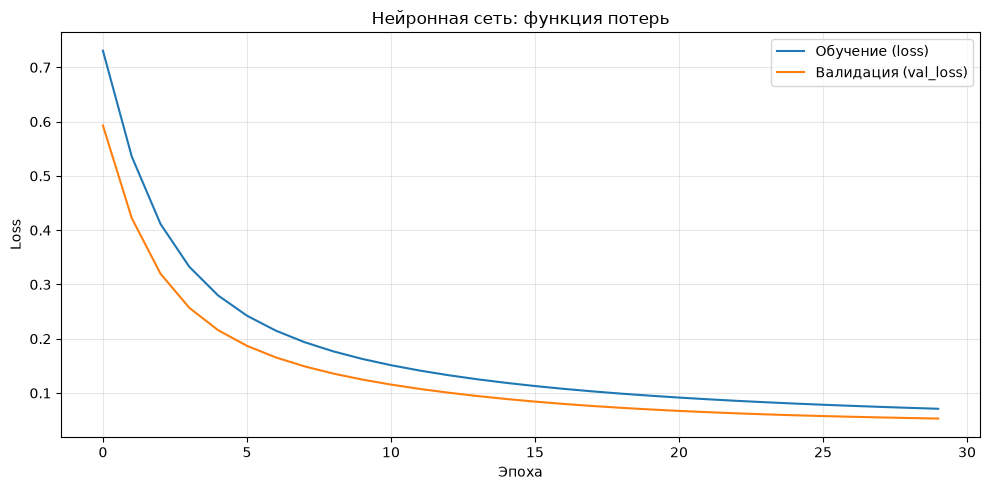

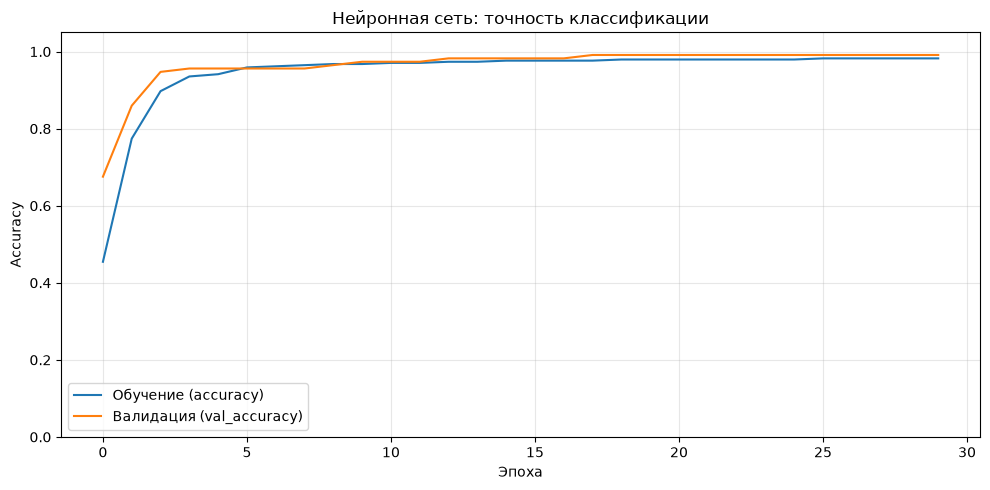

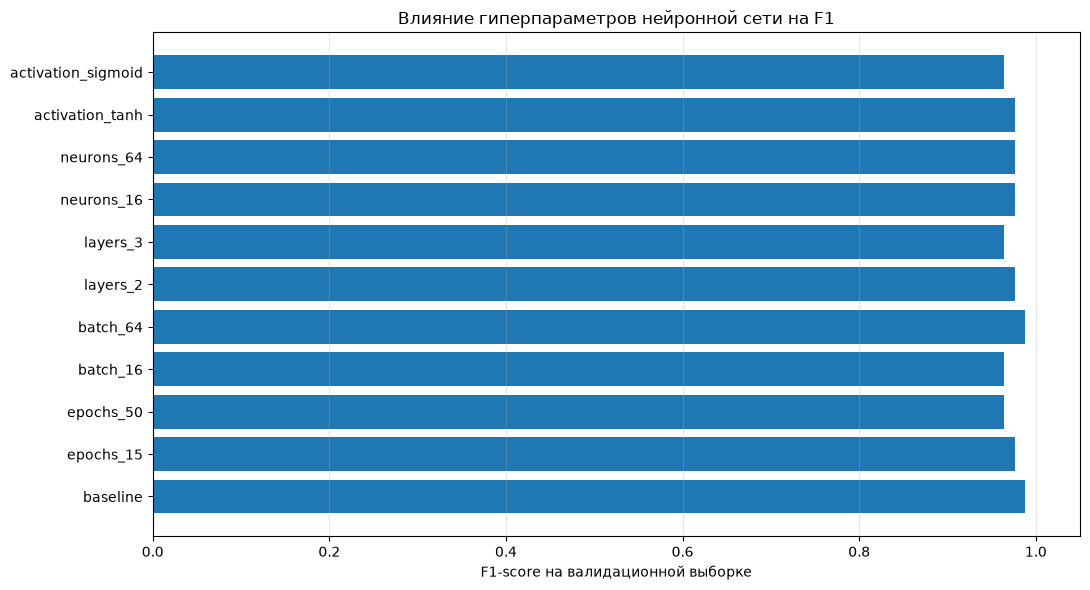

Графики нейронной сети сохранены!


In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    best_nn_history["loss"],
    label="Обучение (loss)"
)

plt.plot(
    best_nn_history["val_loss"],
    label="Валидация (val_loss)"
)

plt.title("Нейронная сеть: функция потерь")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/nn_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    best_nn_history["accuracy"],
    label="Обучение (accuracy)"
)

plt.plot(
    best_nn_history["val_accuracy"],
    label="Валидация (val_accuracy)"
)

plt.title("Нейронная сеть: точность классификации")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/nn_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


plt.figure(figsize=(11, 6))

plt.barh(
    nn_results["Эксперимент"],
    nn_results["F1"]
)

plt.title("Влияние гиперпараметров нейронной сети на F1")
plt.xlabel("F1-score на валидационной выборке")
plt.xlim(0, 1.05)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/nn_hyperparams.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Графики нейронной сети сохранены!")

### 5.1. Анализ экспериментов с нейронной сетью

Для исследования влияния гиперпараметров нейронной сети
проведено 11 экспериментов.

Изменялись количество эпох, размер батча, число скрытых
слоёв, количество нейронов и функции активации.

Наилучшая конфигурация:
- Один скрытый слой;
- 32 нейрона;
- Функция активации ReLU;
- 30 эпох;
- Batch size = 32;
- Оптимизатор Adam;
- Функция потерь Binary Crossentropy.

На валидационной выборке лучшая модель достигла:
Accuracy = 0.9912,
Precision = 1.0000,
Recall = 0.9767,
F1-score = 0.9882,
ROC-AUC = 1.0000.

Увеличение количества эпох с 30 до 50 не улучшило
F1-score, а уменьшение до 15 эпох привело к его снижению.

Использование двух и трёх скрытых слоёв также не
обеспечило улучшения относительно базовой архитектуры.

Изменение числа нейронов и функций активации
не позволило превзойти базовую конфигурацию.

При batch_size=64 был достигнут такой же F1-score,
однако ROC-AUC оказался немного ниже.

На графиках обучения наблюдается постепенное снижение
loss и увеличение accuracy как на обучающей, так и
на валидационной выборке.

Выраженных признаков переобучения выбранной модели
в пределах проведённого обучения не обнаружено.

### 5.2. Мониторинг обучения с помощью TensorBoard

Для визуализации процесса обучения нейронной сети
использован инструмент TensorBoard.

С помощью TensorBoard отслеживались изменения функции
потерь и точности классификации в процессе обучения.

Журналы экспериментов сохранялись в папку
logs/tensorboard с помощью TensorBoard callback.

#### Графики обучения TensorBoard

На рисунке представлены изменения функции потерь
и точности классификации.

![Графики обучения TensorBoard](figures/tensorboard/image3.png)
![Графики обучения TensorBoard](figures/tensorboard/image4.png)

*Рисунок — Мониторинг обучения с помощью TensorBoard.*

#### График валидационной функции потерь

На следующем рисунке показано изменение функции
потерь на валидационной выборке.

![График потерь TensorBoard](figures/tensorboard/image5.png)

*Рисунок — Изменение validation loss в TensorBoard.*

На графиках наблюдается снижение функции потерь
и повышение точности классификации по мере обучения.

Использование TensorBoard позволило сравнить
различные конфигурации нейронной сети и проанализировать
динамику обучения.

## 6. Сравнительный анализ классификаторов

После настройки гиперпараметров проводится итоговая оценка
лучших моделей на независимой тестовой выборке (20%).

Сравниваются следующие классификаторы:
- GaussianNB, MultinomialNB, ComplementNB, BernoulliNB;
- Decision Tree;
- Linear Discriminant Analysis;
- Support Vector Machines;
- k-Nearest Neighbors;
- Нейронная сеть TensorFlow/Keras.

Используются метрики:
- Accuracy;
- Precision;
- Recall;
- F1-score;
- ROC-AUC.

Положительным классом считается злокачественная опухоль (1).

Для визуализации строятся ROC-кривые и столбчатые
диаграммы Accuracy, Precision, Recall и F1-score.

Итоговая оценка проводится без дополнительной настройки
гиперпараметров на тестовой выборке.

In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)

test_models = {
    "GaussianNB": (
        best_bayes_models["GaussianNB"], X_test_scaled
    ),
    "MultinomialNB": (
        best_bayes_models["MultinomialNB"], X_test_minmax
    ),
    "ComplementNB": (
        best_bayes_models["ComplementNB"], X_test_minmax
    ),
    "BernoulliNB": (
        best_bayes_models["BernoulliNB"], X_test_scaled
    ),
    "Decision Tree": (
        best_tree_model, X_test
    ),
    "LDA": (
        best_lda_model, X_test_scaled
    ),
    "SVM": (
        best_svm_model, X_test_scaled
    ),
    "kNN": (
        best_knn_model, X_test_scaled
    )
}

test_results_list = []
roc_data = {}

def add_test_result(name, y_pred, y_score):

    metrics = {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    }

    test_results_list.append(metrics)

    # Данные для ROC-кривой
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_data[name] = (fpr, tpr)


for name, (model, X_data) in test_models.items():

    y_pred = model.predict(X_data)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_data)[:, 1]
    else:
        y_score = model.decision_function(X_data)

    add_test_result(name, y_pred, y_score)


best_nn_model = tf.keras.models.load_model(
    "results/best_nn.keras"
)

X_test_nn = np.asarray(X_test_scaled, dtype=np.float32)

nn_prob = best_nn_model.predict(
    X_test_nn, verbose=0
).ravel()

nn_pred = (nn_prob >= 0.5).astype(int)

add_test_result(
    "TensorFlow NN",
    nn_pred,
    nn_prob
)


final_results = pd.DataFrame(test_results_list)

final_results = final_results.sort_values(
    ["F1", "Recall", "ROC-AUC"],
    ascending=False,
    kind="stable"
).reset_index(drop=True)

print("Итоговое сравнение на тестовой выборке:")
display(final_results.round(4))

print("\nЛучшая модель по F1-score:")
print(final_results.iloc[0]["Модель"])

final_results.to_csv(
    "results/final_test_comparison.csv",
    index=False
)

print("\nИтоговые результаты сохранены!")

Итоговое сравнение на тестовой выборке:


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,TensorFlow NN,0.9912,1.0000,0.9762,0.9880,0.9980
1,SVM,0.9825,1.0000,0.9524,0.9756,0.9947
2,LDA,0.9737,1.0000,0.9286,0.9630,0.9924
3,Decision Tree,0.9649,0.9750,0.9286,0.9512,0.9534
4,BernoulliNB,0.9386,0.8889,0.9524,0.9195,0.9858
5,kNN,0.9386,0.9268,0.9048,0.9157,0.9315
6,GaussianNB,0.9298,0.9250,0.8810,0.9024,0.9914
7,ComplementNB,0.8333,0.8108,0.7143,0.7595,0.8780
8,MultinomialNB,0.8158,0.9565,0.5238,0.6769,0.9074



Лучшая модель по F1-score:
TensorFlow NN

Итоговые результаты сохранены!


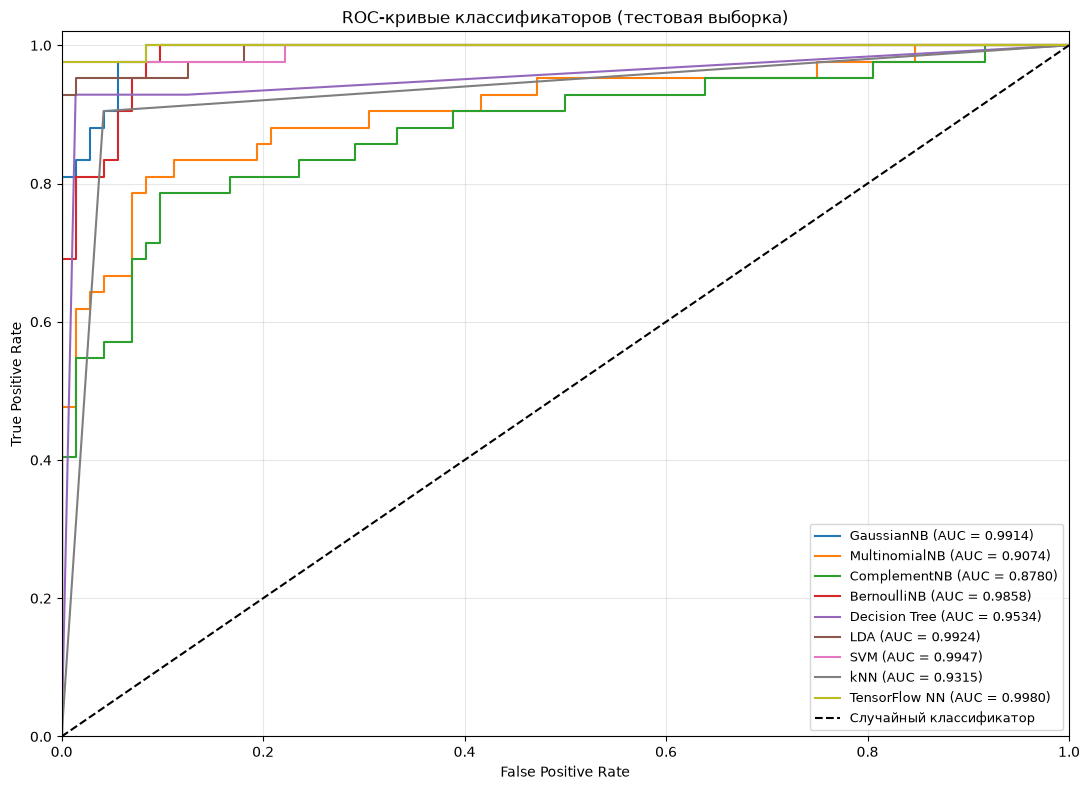

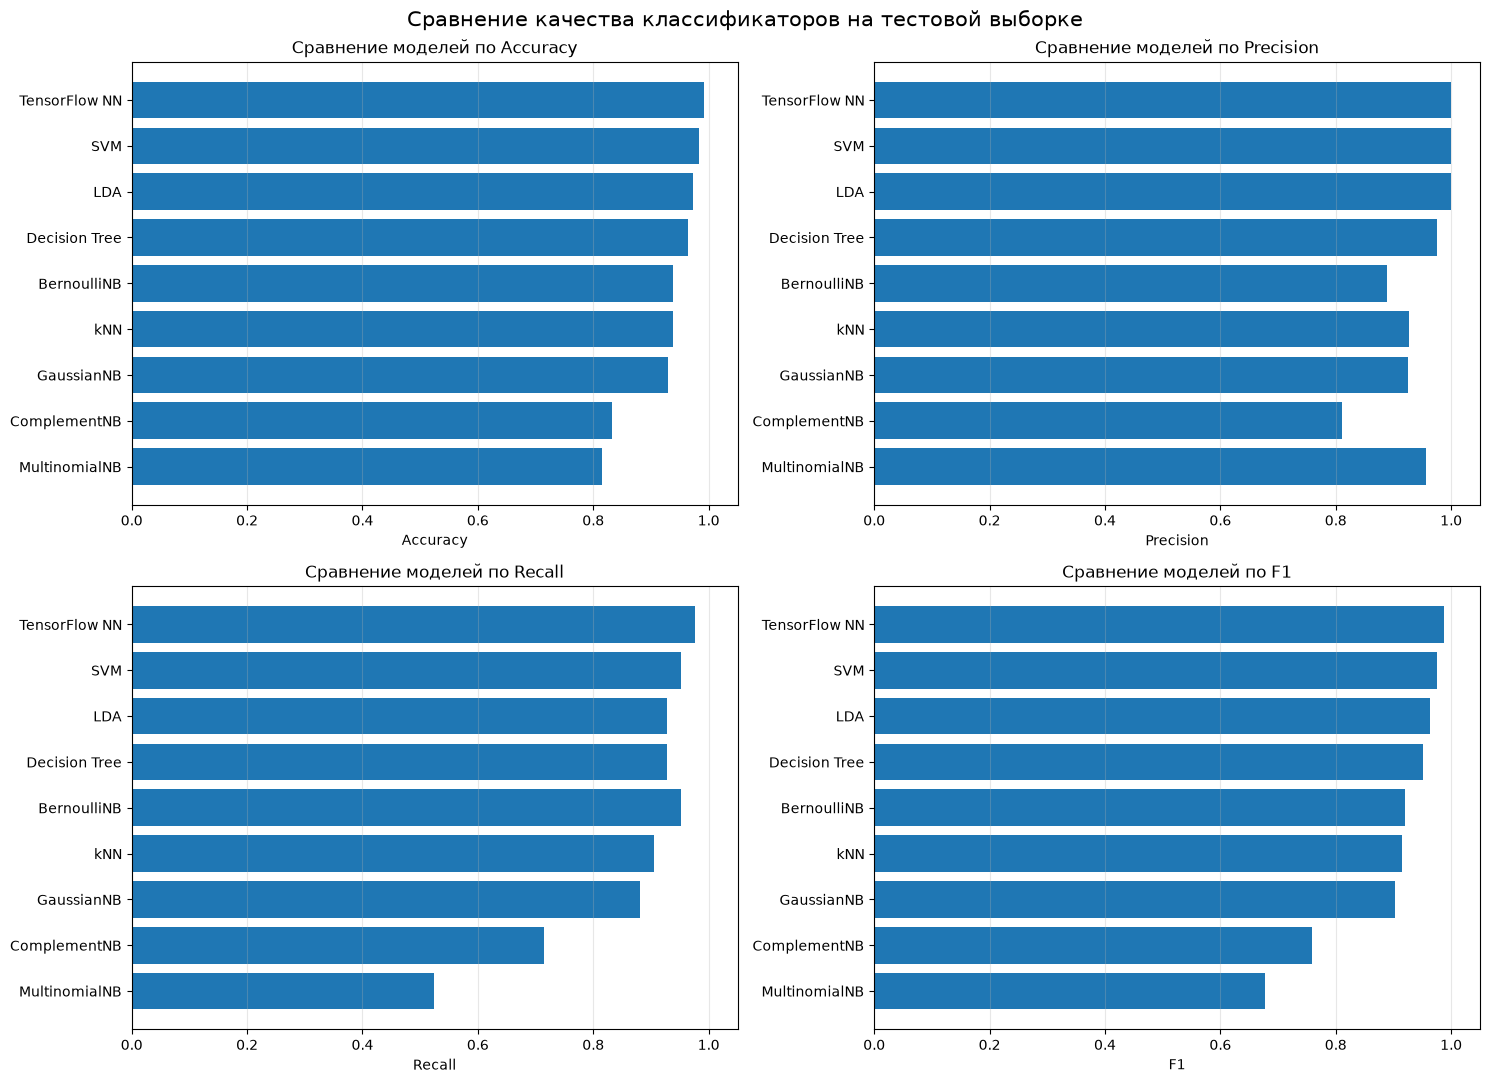

Итоговые графики сохранены!


In [20]:
plt.figure(figsize=(11, 8))

for name, (fpr, tpr) in roc_data.items():

    auc_value = final_results.loc[
        final_results["Модель"] == name, "ROC-AUC"
    ].iloc[0]

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Случайный классификатор"
)

plt.title("ROC-кривые классификаторов (тестовая выборка)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/final_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

plot_data = final_results.iloc[::-1]

for ax, metric in zip(axes.flat, metrics_to_plot):

    ax.barh(
        plot_data["Модель"],
        plot_data[metric]
    )

    ax.set_title(f"Сравнение моделей по {metric}")
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1.05)
    ax.grid(axis="x", alpha=0.3)

plt.suptitle(
    "Сравнение качества классификаторов на тестовой выборке",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "figures/final_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Итоговые графики сохранены!")

## 7. Сравнительный анализ результатов классификации

В ходе лабораторной работы было исследовано пять методов классификации из библиотеки Scikit-Learn: наивный байесовский классификатор, дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод ближайших соседей. Дополнительно была реализована нейронная сеть с использованием TensorFlow/Keras.

Для каждого метода проведён подбор гиперпараметров на валидационной выборке. Итоговая оценка выполнена на независимой тестовой выборке, содержащей 114 наблюдений.

Наилучшее качество классификации продемонстрировала нейронная сеть TensorFlow с одним скрытым слоем из 32 нейронов и функцией активации ReLU. Модель достигла Accuracy = 0.9912, Precision = 1.0000, Recall = 0.9762, F1-score = 0.9880 и ROC-AUC = 0.9980.

Среди классических методов машинного обучения лучшие результаты показал SVM с ядром RBF, параметром C = 10 и gamma = scale. Значение F1-score составило 0.9756, а Accuracy — 0.9825.

Линейный дискриминантный анализ также продемонстрировал высокую эффективность: Accuracy = 0.9737 и F1-score = 0.9630.

Дерево решений обеспечило F1-score = 0.9512. При исследовании глубины дерева было установлено, что чрезмерное увеличение глубины может приводить к переобучению.

Метод kNN и байесовские классификаторы показали более низкие результаты по сравнению с лидирующими подходами. Среди вариантов Naive Bayes наибольший F1-score на тестовой выборке обеспечил BernoulliNB — 0.9195.

Наименьший F1-score получен у MultinomialNB — 0.6769, что указывает на менее удачное соответствие этого алгоритма особенностям используемых данных и выбранной процедуре подготовки признаков.

Анализ ROC-кривых подтвердил высокую способность нейронной сети различать классы. Значение ROC-AUC = 0.9980 оказалось максимальным среди исследованных моделей.

Таким образом, **лучшим подходом для выбранного датасета по результатам проведённого эксперимента является нейронная сеть TensorFlow/Keras**. Однако оценка выполнена на ограниченной тестовой выборке, поэтому для подтверждения устойчивости результатов потребовалось бы дополнительное исследование.

## 8. Заключение

В ходе лабораторной работы были изучены и практически реализованы методы классификации данных с использованием библиотек Scikit-Learn и TensorFlow/Keras.

Для проведения экспериментов использован датасет Breast Cancer Wisconsin (Diagnostic), содержащий 569 наблюдений и 30 числовых признаков. Выполнен предварительный анализ данных, проведена стандартизация признаков и организовано стратифицированное разбиение выборки в соотношении 60/20/20.

Реализованы и исследованы четыре варианта наивного байесовского классификатора, дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод ближайших соседей.

Проведён подбор гиперпараметров, изучено их влияние на качество классификации. Для оценки использованы метрики Accuracy, Precision, Recall, F1-score и ROC-AUC.

Дополнительно разработана полносвязная нейронная сеть TensorFlow/Keras. Выполнено 11 экспериментов с изменением количества эпох, размера батча, числа скрытых слоёв и нейронов, а также функций активации. Построены графики обучения и валидации. Для мониторинга обучения использован инструмент TensorBoard.

В результате сравнительного анализа установлено, что наилучшее качество на тестовой выборке обеспечила нейронная сеть TensorFlow/Keras с F1-score = 0.9880 и Accuracy = 0.9912. Среди классических методов лучшим оказался SVM с F1-score = 0.9756.

Таким образом, цель лабораторной работы достигнута: изучены методы классификации, исследовано влияние гиперпараметров, освоены основы разработки нейронных сетей и применения TensorBoard для анализа процесса обучения.